In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv("data.csv")
df

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
0,2002,36,2002-09-01,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19
1,2002,37,2002-09-08,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15
2,2002,38,2002-09-15,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13
3,2002,39,2002-09-22,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10
4,2002,40,2002-09-29,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1248,2026,31,2026-08-02,9.7,29.10,76.0,18.95,1004.50,25.00,7.00,4.0,682,438,103.0,1252
1249,2026,32,2026-08-09,10.3,31.70,73.0,21.44,1000.05,26.10,9.10,5.0,713,356,89.0,1190
1250,2026,33,2026-08-16,7.9,29.70,82.0,13.81,1003.10,26.00,9.50,3.0,735,245,65.0,1077
1251,2026,34,2026-08-23,6.7,29.90,80.0,14.01,1001.60,26.70,8.30,3.0,846,206,60.0,1148


In [4]:
mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
flu_col = ["H1", "H3", "B", "AandB"]

In [5]:
X = df[mete_col].to_numpy()
y = df[flu_col[0]].to_numpy()

In [78]:
y_train

array([ 0,  0,  0, ...,  0, 28,  6], shape=(1127,))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=32)

# ---
y_train_clean = y_train.flatten()
y_test_clean = y_test.flatten()

y_train_log = np.log1p(y_train_clean)

boosting = HistGradientBoostingRegressor(
    max_iter=150,
    max_depth=5,
    learning_rate=0.05,
    random_state=42
)
boosting.fit(X_train, y_train_log)
y_pred_log = boosting.predict(X_test)
y_pred = np.expm1(y_pred_log)

# --- 
y_train = np.clip(y_train, 0, 600)
    # ! change outlier values (is it correct?)

regressor = RandomForestRegressor(n_estimators=100, random_state=32)
regressor.fit(X_train, y_train_log)

y_pred_log = regressor.predict(X_test)
y_pred = np.expm1(y_pred_log)
print(f"R-square: {r2_score(y_test_clean, y_pred)}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_clean, y_pred)}")


R-square: -0.13921684823672154
Mean Squared Error (MSE): 37123.701124406456


In [83]:
regressor.feature_importances_ 

array([0.12353215, 0.10052632, 0.14213419, 0.12414341, 0.13677197,
       0.13556575, 0.13649667, 0.10082954])

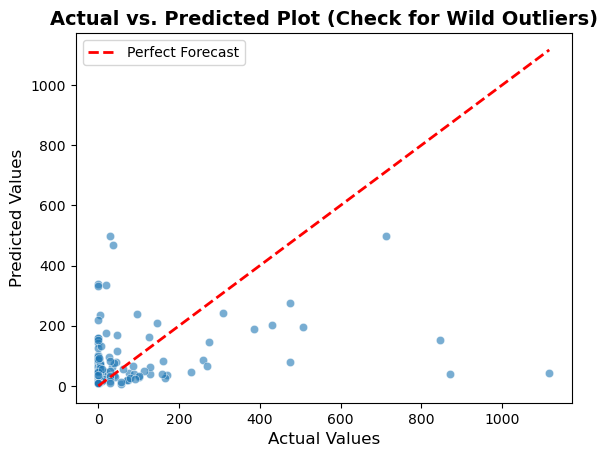

In [67]:
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
max_val = max(max(y_test), max(y_pred))
min_val = min(min(y_test), min(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Forecast")

# 4. Labels and Title
plt.xlabel("Actual Values", fontsize=12)
plt.ylabel("Predicted Values", fontsize=12)
plt.title("Actual vs. Predicted Plot (Check for Wild Outliers)", fontsize=14, fontweight="bold")
plt.legend()

# 5. Display the plot
plt.show()

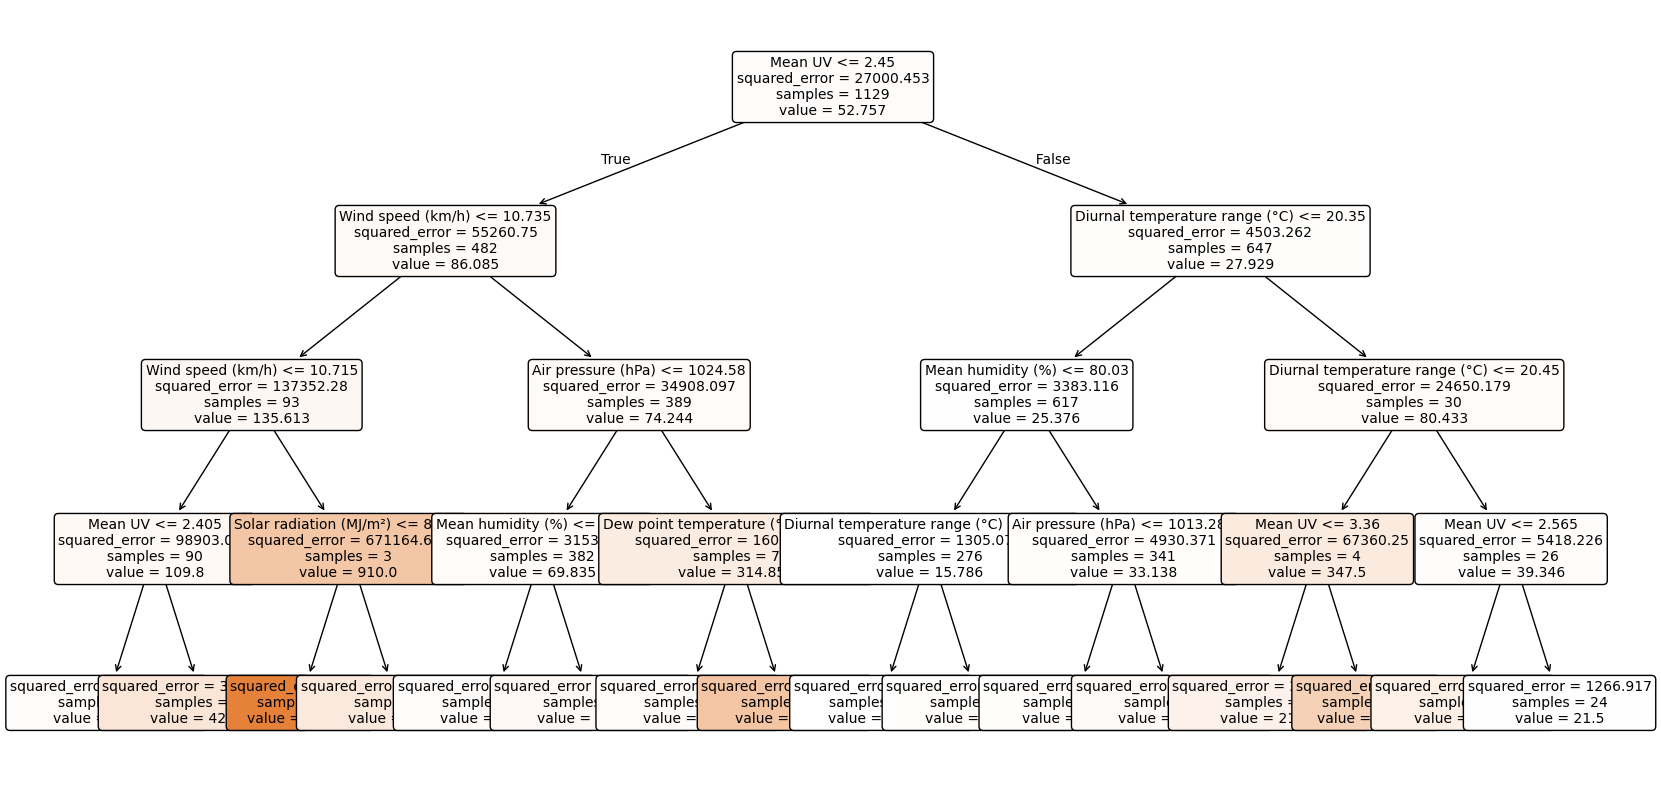

In [ ]:
plt.figure(figsize=(20, 10))
plot_tree(
    regressor,
    feature_names=mete_col,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

In [ ]:
rfr = RandomForestRegressor(n_estimators=20, max_features="sqrt", max_depth=5, random_state=24).fit(X_train, y_train)

prediction = rfr.predict(X_test)
mse = mean_squared_error(y_test, prediction)
rmse = mse ** 0.5
print(f"Mean squared error: {mse}")
print(f"Root squared mean square error: {rmse}")

Mean squared error: 33166.19799734766
Root squared mean square error: 182.1158916661247


In [ ]:
[x for x in range(0, 1000, 100)]

In [19]:
grid = {
    "n_estimators": [x for x in range(0, 1000, 100)],
    "max_features": ["sqrt", "log2"],
    "max_depth": [3, 4, 5, 6, 7],
    "random_state": [18, 24, 42]
}

CV_rfr = GridSearchCV(estimator=RandomForestRegressor(), param_grid=grid, cv=5)
result = CV_rfr.fit(X_train, y_train)

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
150 fits failed out of a total of 1500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
150 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\base.py", line 471, in _validate_params


In [20]:
result

,estimator,RandomForestRegressor()
,param_grid,"{'max_depth': [3, 4, ...], 'max_features': ['sqrt', 'log2'], 'n_estimators': [0, 100, ...], 'random_state': [18, 24, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200
